In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Kaggle / UN Global Health Outcomes Dataset
# encoding='latin1' handles the special en-dash character in the original headers
df = pd.read_csv('health-outcomes.csv', encoding='latin1')

# Replace corrupt en-dash character 'Ð' with a clean hyphen
df.columns = df.columns.str.replace('Ð', '-', regex=False).str.strip()

In [3]:
df.head()

,Country,Infants exclusively breastfed (% ages 0-5 months) 2008-2013,Infants lacking immunization (% of one-year-olds) DTP 2013,Infants lacking immunization (% of one-year-olds) Measles 2013,"Mortality rates (per 1,000 live births) Infant 2013","Mortality rates (per 1,000 live births) Under-five 2013",Child malnutrition (% under age 5) Stunting (moderate or severe) 2008-2013,"Adult mortality rate (per 1,000 people) Female 2013","Adult mortality rate (per 1,000 people) Male 2013","Deaths due to Malaria (per 100,000 people) 2012","Deaths due to Tuberculosis (per 100,000 people) 2012","HIV prevalence, adult (% ages 15-49) 2013",Life expectancy at age 60 (years) 2010/2015,"Physicians (per 10,000 people) 2001-2013",Public health expenditure (% of GDP) 2013
0,Norway,NaN,1.0,7.0,2.3,2.8,NaN,47.0,73.0,NaN,0.1,NaN,24.0,37.4,9.6
1,Netherlands,NaN,1.0,4.0,3.3,4.0,NaN,54.0,69.0,NaN,0.2,NaN,23.5,31.5,12.9
2,Sweden,NaN,1.0,3.0,2.4,3.0,NaN,43.0,69.0,NaN,0.1,NaN,24.1,32.7,9.7
3,Korea (Republic of),NaN,1.0,1.0,3.2,3.7,2.5,38.0,93.0,0.0,5.4,NaN,24.0,21.4,7.2
4,Luxembourg,NaN,1.0,5.0,1.6,2.0,NaN,50.0,79.0,NaN,0.4,NaN,23.4,28.2,7.1


In [4]:
# Problem: Predict High Risk (1) vs Low Risk (0) Under-Five Child Mortality
median_u5 = df['Mortality rates (per 1,000 live births) Under-five 2013'].median()
df['target'] = (df['Mortality rates (per 1,000 live births) Under-five 2013'] >= median_u5).astype(int)

# Drop direct target leak columns and textual country identifiers
df.drop(columns=[
    'Country', 
    'Mortality rates (per 1,000 live births) Infant 2013', 
    'Mortality rates (per 1,000 live births) Under-five 2013'
], inplace=True)

df.head()

C:\Users\athar\AppData\Local\Temp\ipykernel_29364\545873843.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=[


,Infants exclusively breastfed (% ages 0-5 months) 2008-2013,Infants lacking immunization (% of one-year-olds) DTP 2013,Infants lacking immunization (% of one-year-olds) Measles 2013,Child malnutrition (% under age 5) Stunting (moderate or severe) 2008-2013,"Adult mortality rate (per 1,000 people) Female 2013","Adult mortality rate (per 1,000 people) Male 2013","Deaths due to Malaria (per 100,000 people) 2012","Deaths due to Tuberculosis (per 100,000 people) 2012","HIV prevalence, adult (% ages 15-49) 2013",Life expectancy at age 60 (years) 2010/2015,"Physicians (per 10,000 people) 2001-2013",Public health expenditure (% of GDP) 2013,target
0,NaN,1.0,7.0,NaN,47.0,73.0,NaN,0.1,NaN,24.0,37.4,9.6,0
1,NaN,1.0,4.0,NaN,54.0,69.0,NaN,0.2,NaN,23.5,31.5,12.9,0
2,NaN,1.0,3.0,NaN,43.0,69.0,NaN,0.1,NaN,24.1,32.7,9.7,0
3,NaN,1.0,1.0,2.5,38.0,93.0,0.0,5.4,NaN,24.0,21.4,7.2,0
4,NaN,1.0,5.0,NaN,50.0,79.0,NaN,0.4,NaN,23.4,28.2,7.1,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 13 columns):
 #   Column                                                                      Non-Null Count  Dtype  
---  ------                                                                      --------------  -----  
 0   Infants exclusively breastfed (% ages 0-5 months) 2008-2013                 139 non-null    float64
 1   Infants lacking immunization (% of one-year-olds) DTP 2013                  208 non-null    float64
 2   Infants lacking immunization (% of one-year-olds) Measles 2013              208 non-null    float64
 3   Child malnutrition (% under age 5) Stunting (moderate or severe) 2008-2013  157 non-null    float64
 4   Adult mortality rate (per 1,000 people) Female 2013                         207 non-null    float64
 5   Adult mortality rate (per 1,000 people) Male 2013                           207 non-null    float64
 6   Deaths due to Malaria (per 100,000 people) 2012              

In [6]:
print("Duplicate rows count:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Duplicate rows count after cleanup:", df.duplicated().sum())

Duplicate rows count: 0
Duplicate rows count after cleanup: 0


C:\Users\athar\AppData\Local\Temp\ipykernel_29364\1604826352.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [7]:
print("Missing values before imputation:\n", df.isnull().sum())

# Impute median values for all numeric indicator columns
num_cols_all = df.select_dtypes(include=np.number).columns.drop('target')
for col in num_cols_all:
    df[col] = df[col].fillna(df[col].median())

print("\nMissing values after imputation:\n", df.isnull().sum())

Missing values before imputation:
 Infants exclusively breastfed (% ages 0-5 months) 2008-2013                    71
Infants lacking immunization (% of one-year-olds) DTP 2013                      2
Infants lacking immunization (% of one-year-olds) Measles 2013                  2
Child malnutrition (% under age 5) Stunting (moderate or severe) 2008-2013     53
Adult mortality rate (per 1,000 people) Female 2013                             3
Adult mortality rate (per 1,000 people) Male 2013                               3
Deaths due to Malaria (per 100,000 people) 2012                               106
Deaths due to Tuberculosis (per 100,000 people) 2012                            1
HIV prevalence, adult (% ages 15-49) 2013                                      79
Life expectancy at age 60 (years) 2010/2015                                    10
Physicians (per 10,000 people) 2001-2013                                        6
Public health expenditure (% of GDP) 2013                      

Numeric features for outlier check: Index(['Infants exclusively breastfed (% ages 0-5 months) 2008-2013',
       'Infants lacking immunization (% of one-year-olds) DTP 2013',
       'Infants lacking immunization (% of one-year-olds) Measles 2013',
       'Child malnutrition (% under age 5) Stunting (moderate or severe) 2008-2013',
       'Adult mortality rate (per 1,000 people) Female 2013',
       'Adult mortality rate (per 1,000 people) Male 2013',
       'Deaths due to Malaria (per 100,000 people) 2012',
       'Deaths due to Tuberculosis (per 100,000 people) 2012',
       'HIV prevalence, adult (% ages 15-49) 2013',
       'Life expectancy at age 60 (years) 2010/2015',
       'Physicians (per 10,000 people) 2001-2013',
       'Public health expenditure (% of GDP) 2013'],
      dtype='str')


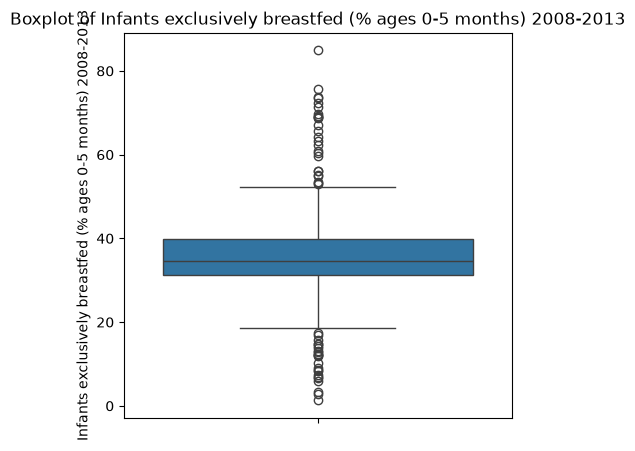

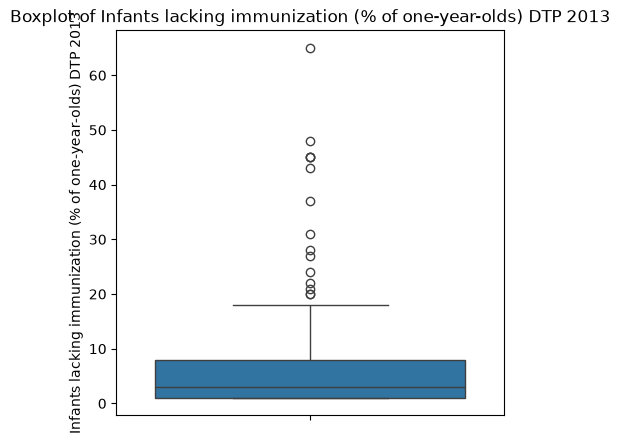

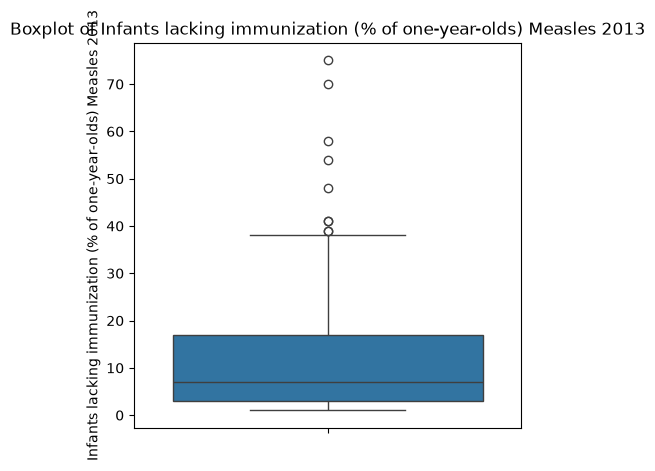

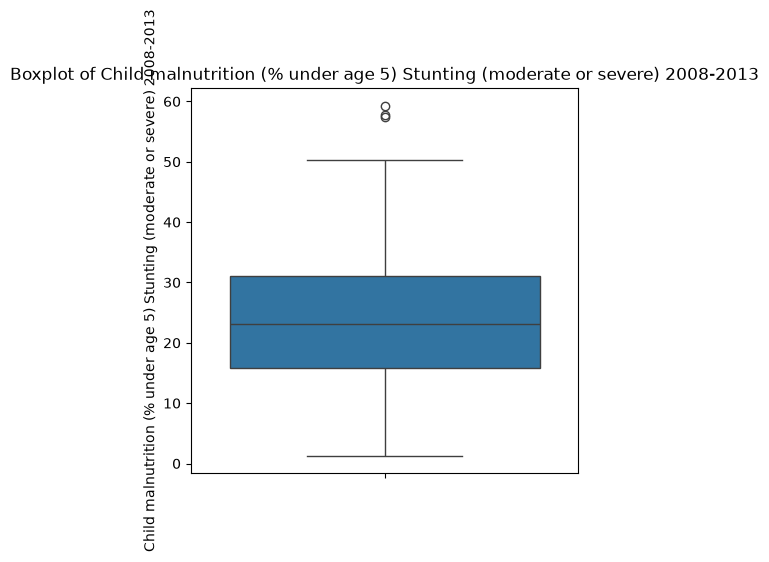

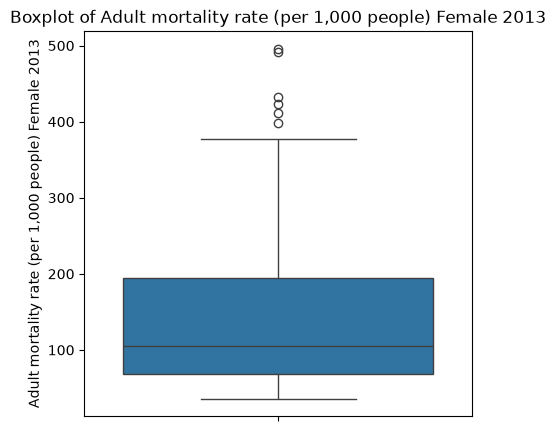

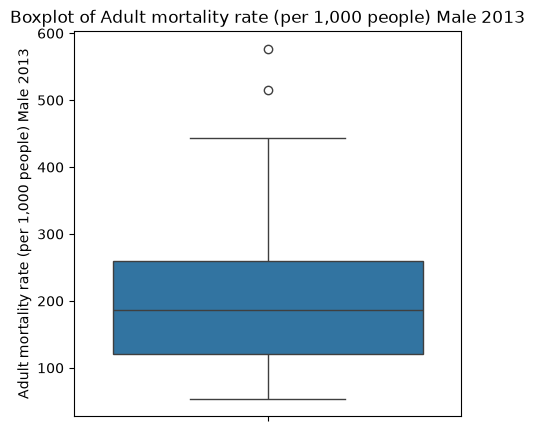

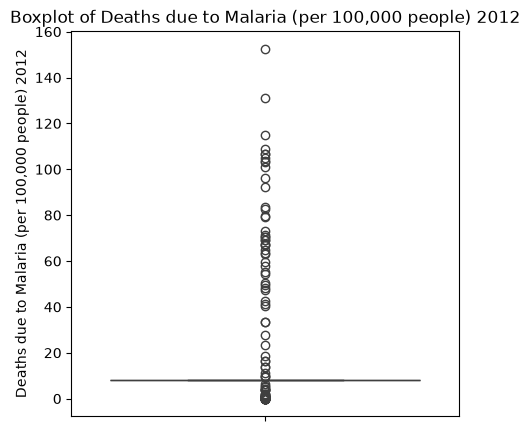

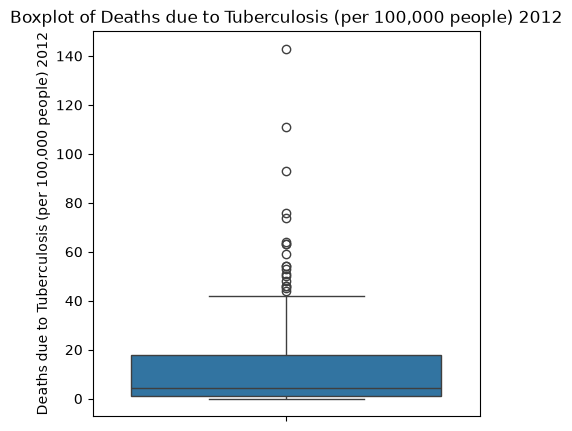

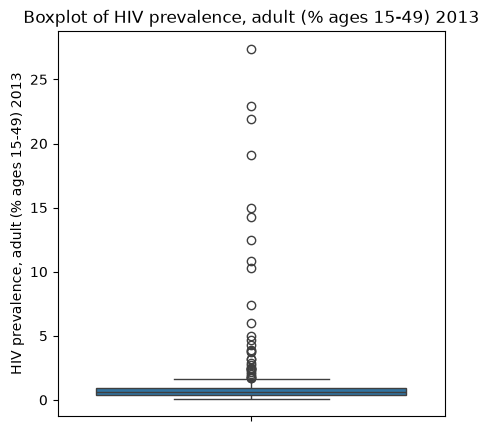

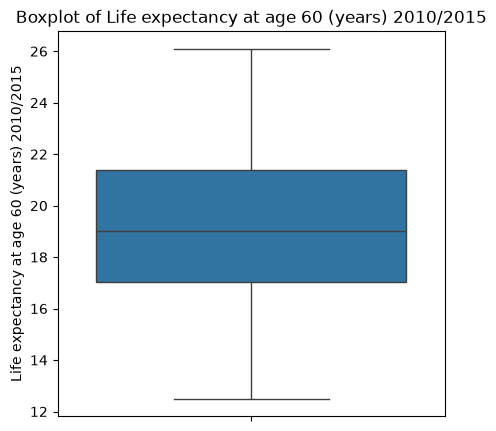

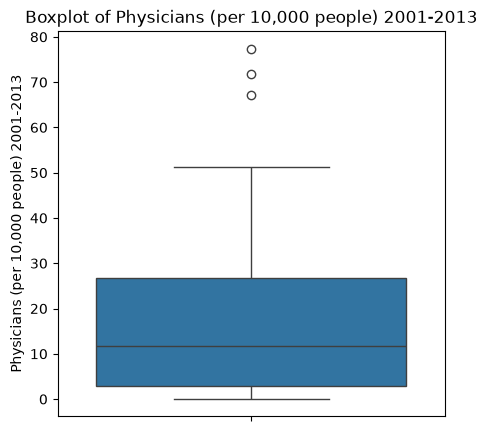

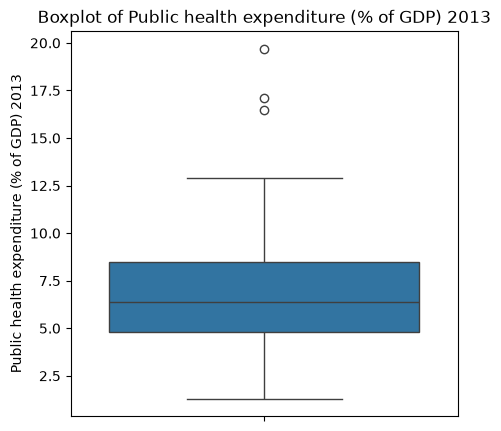

In [8]:
# Select continuous numeric feature columns
num_col = df.select_dtypes(include=np.number).columns.drop('target')
print("Numeric features for outlier check:", num_col)

for col in num_col:
    plt.figure(figsize=(5, 5))
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [9]:
# Using IQR clipping prevents dropping all rows belonging to class 1
for col in num_col:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Clip extreme values to upper and lower bounds
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
    print(f"Outliers in {col} capped")

print("\nShape after outlier treatment:", df.shape)
print("Target class balance:\n", df['target'].value_counts())

Outliers in Infants exclusively breastfed (% ages 0-5 months) 2008-2013 capped
Outliers in Infants lacking immunization (% of one-year-olds) DTP 2013 capped
Outliers in Infants lacking immunization (% of one-year-olds) Measles 2013 capped
Outliers in Child malnutrition (% under age 5) Stunting (moderate or severe) 2008-2013 capped
Outliers in Adult mortality rate (per 1,000 people) Female 2013 capped
Outliers in Adult mortality rate (per 1,000 people) Male 2013 capped
Outliers in Deaths due to Malaria (per 100,000 people) 2012 capped
Outliers in Deaths due to Tuberculosis (per 100,000 people) 2012 capped
Outliers in HIV prevalence, adult (% ages 15-49) 2013 capped
Outliers in Life expectancy at age 60 (years) 2010/2015 capped
Outliers in Physicians (per 10,000 people) 2001-2013 capped
Outliers in Public health expenditure (% of GDP) 2013 capped

Shape after outlier treatment: (210, 13)
Target class balance:
 target
0    106
1    104
Name: count, dtype: int64


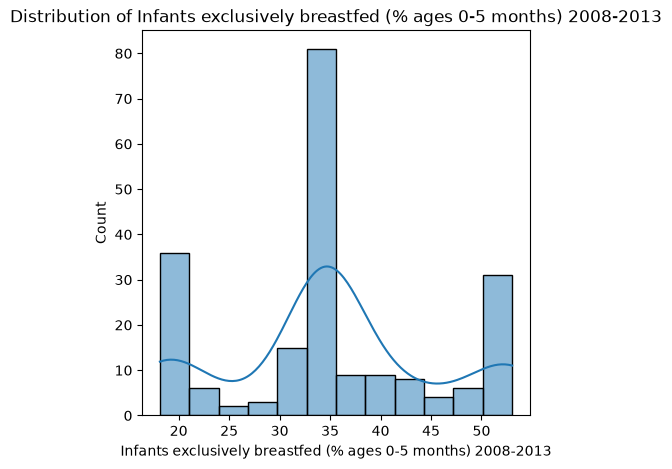

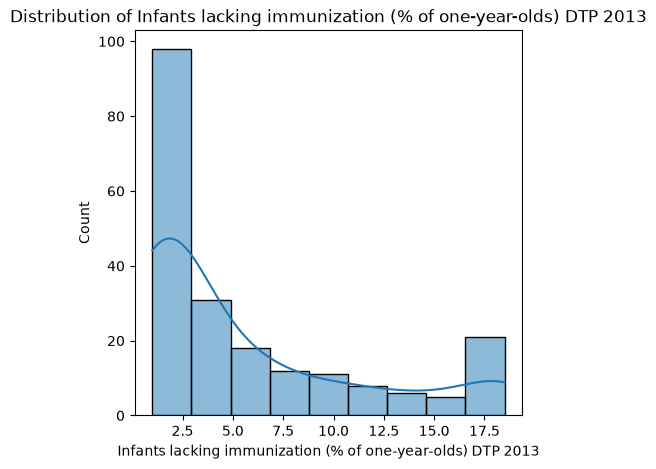

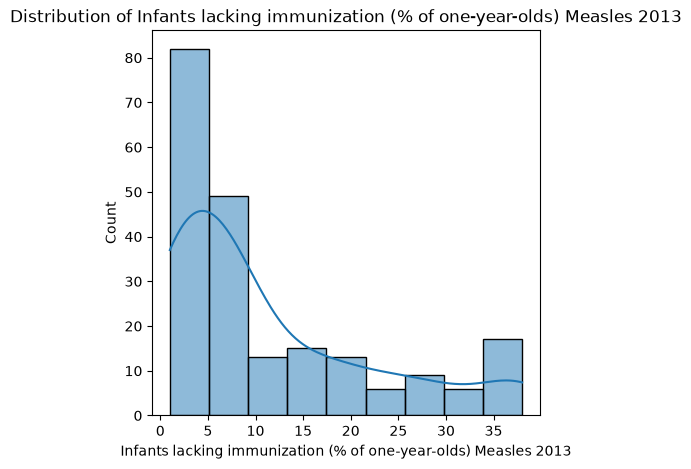

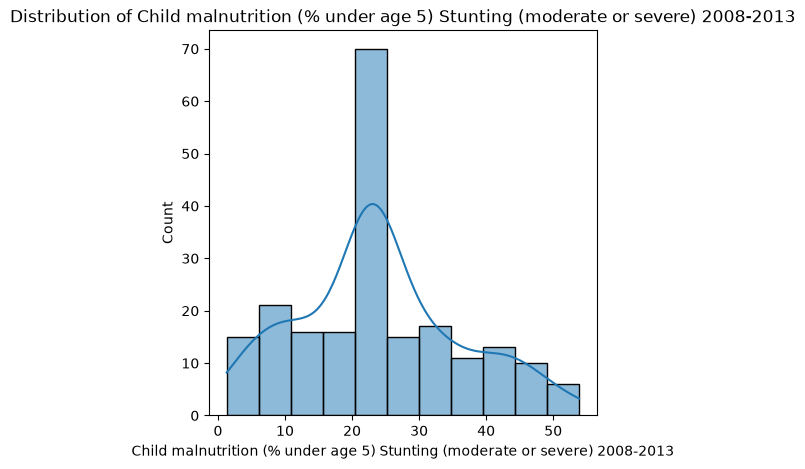

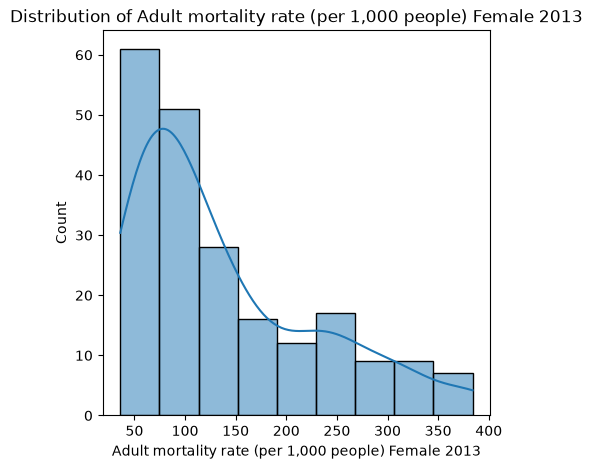

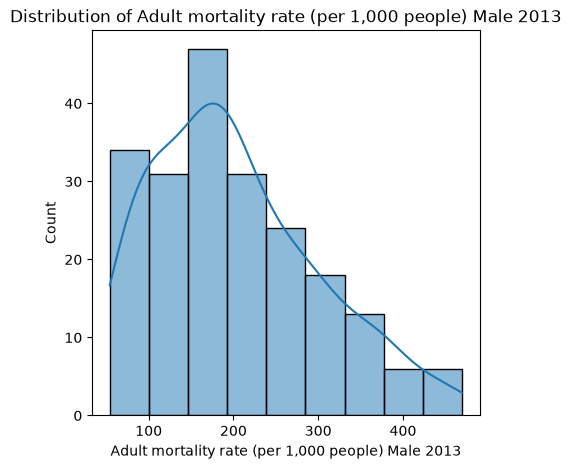

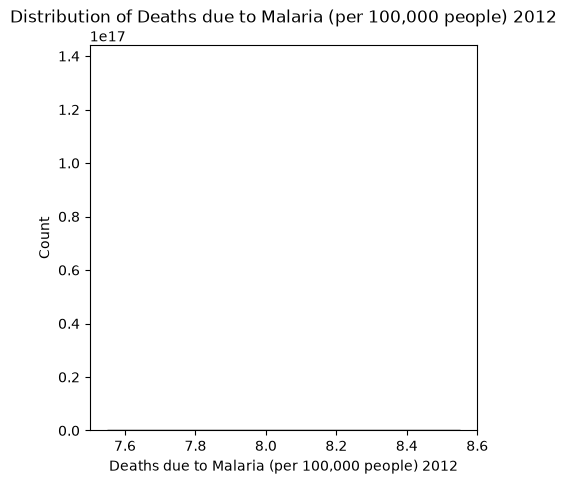

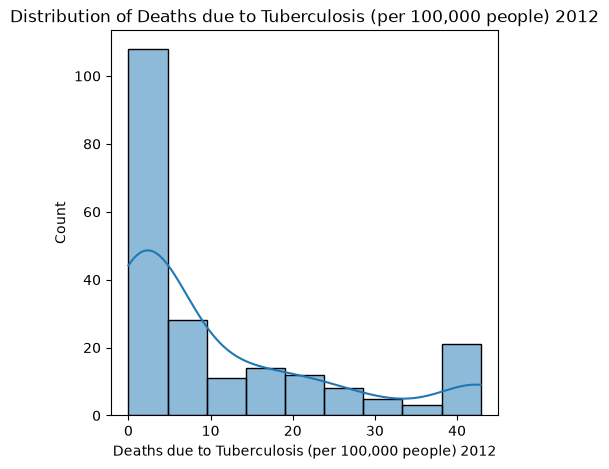

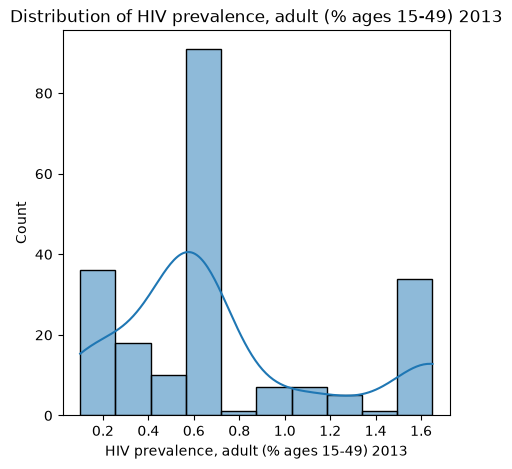

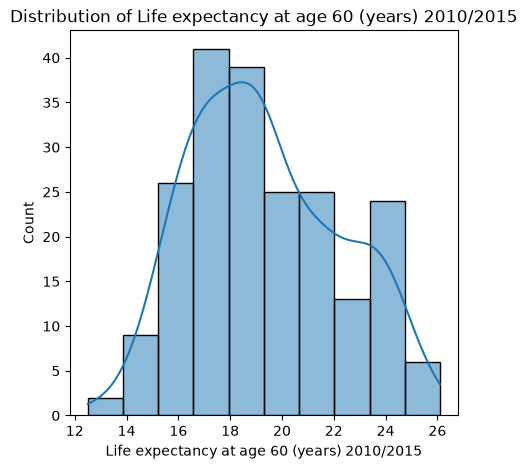

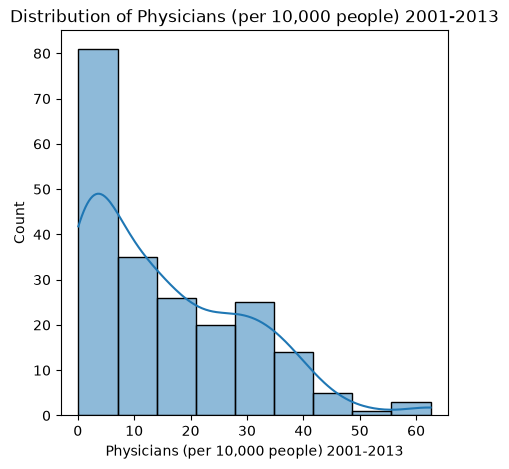

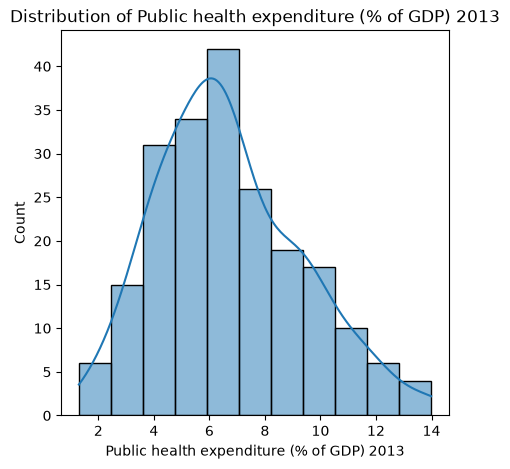

In [10]:
# Univariate distribution of numerical features
for col in num_col:
    plt.figure(figsize=(5, 5))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

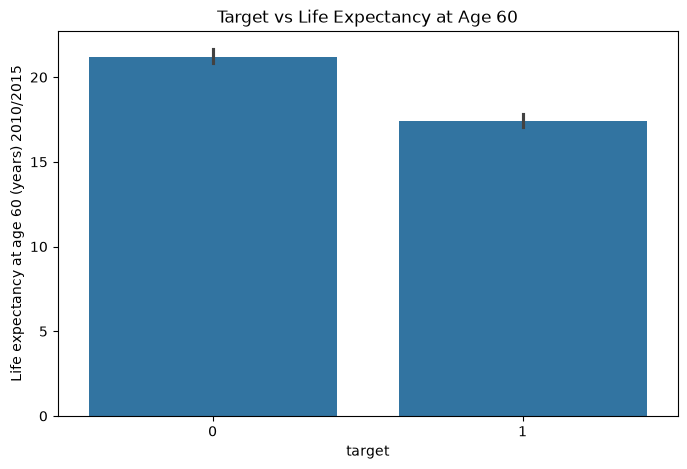

In [11]:
# Bivariate analysis: Target vs Life Expectancy at Age 60
plt.figure(figsize=(8, 5))
sns.barplot(x='target', y='Life expectancy at age 60 (years) 2010/2015', data=df)
plt.title("Target vs Life Expectancy at Age 60")
plt.show()

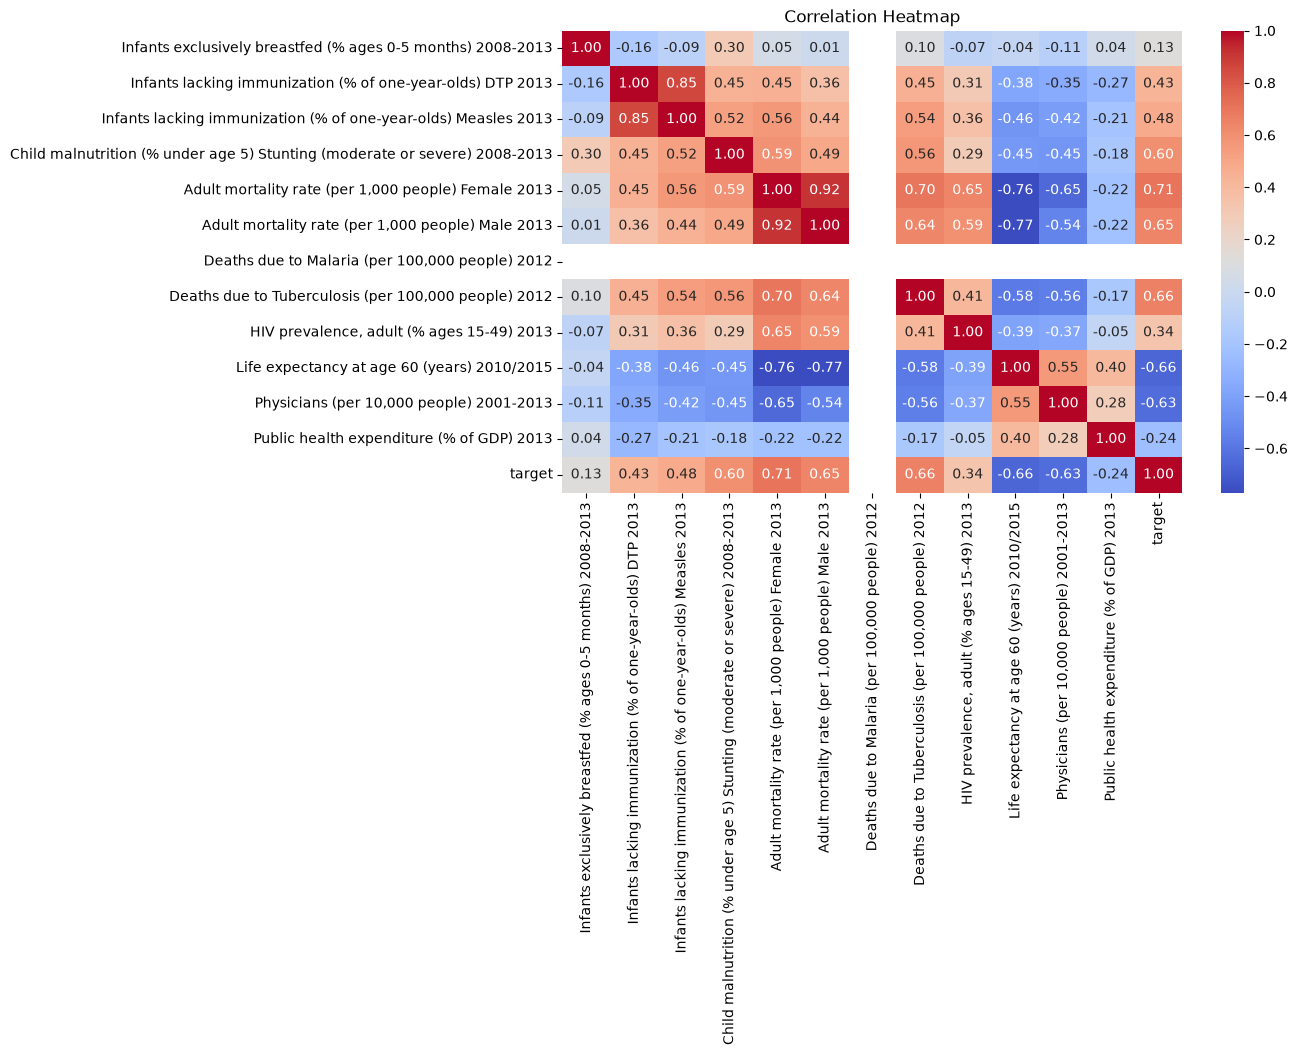

In [12]:
# Correlation Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap="coolwarm", fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [13]:
# Check for any remaining non-numeric categorical columns
cat_col = df.select_dtypes(include='object').columns
print("Categorical columns:", cat_col)

if len(cat_col) > 0:
    df = pd.get_dummies(df, columns=cat_col, drop_first=True, dtype=int)

Categorical columns: Index([], dtype='str')


In [14]:
# Separate features and target
X = df.drop('target', axis=1)
y = df['target']

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Features shape (X): (210, 12)
Target shape (y): (210,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("Target distribution in y_test:\n", y_test.value_counts())

Training set shape: (168, 12)
Testing set shape: (42, 12)
Target distribution in y_test:
 target
0    21
1    21
Name: count, dtype: int64


In [16]:
# Models and evaluation metrics
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    confusion_matrix, 
    ConfusionMatrixDisplay
)

In [17]:
model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42,
    learning_rate=1.0
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("AdaBoost Predictions:\n", y_pred)

AdaBoost Predictions:
 [0 1 0 1 0 1 0 0 1 0 0 1 0 1 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 1 0 0 1 1 1 1
 1 0 0 1 1]


In [18]:
print("AdaBoost Training accuracy:", model.score(X_train, y_train))
print("AdaBoost Testing accuracy:", model.score(X_test, y_test))

print("\nAdaBoost Classification Report:\n")
print(classification_report(y_test, y_pred))

AdaBoost Training accuracy: 1.0
AdaBoost Testing accuracy: 0.9761904761904762

AdaBoost Classification Report:

              precision    recall  f1-score   support

           0       0.95      1.00      0.98        21
           1       1.00      0.95      0.98        21

    accuracy                           0.98        42
   macro avg       0.98      0.98      0.98        42
weighted avg       0.98      0.98      0.98        42



In [19]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest Training accuracy:", rf.score(X_train, y_train))
print("Random Forest Testing accuracy:", rf.score(X_test, y_test))

Random Forest Training accuracy: 1.0
Random Forest Testing accuracy: 0.9761904761904762


Random Forest Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.95      0.98        21
           1       0.95      1.00      0.98        21

    accuracy                           0.98        42
   macro avg       0.98      0.98      0.98        42
weighted avg       0.98      0.98      0.98        42



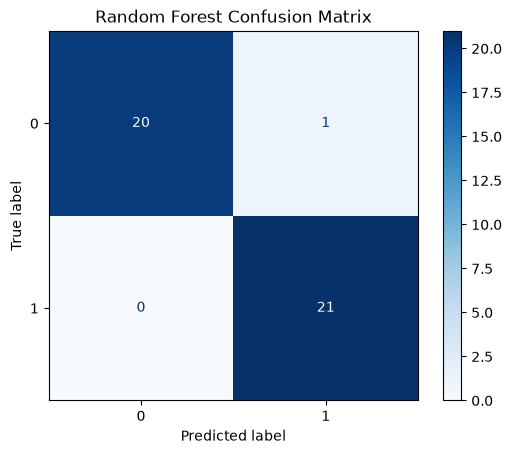

In [20]:
# Project guidelines: At least 4 metrics (Accuracy, Precision, Recall, F1-Score, Confusion Matrix)
print("Random Forest Classification Report:\n")
print(classification_report(y_test, y_pred_rf))

cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.show()

C:\Users\athar\AppData\Local\Temp\ipykernel_29364\2853817793.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=importances.index, palette="viridis")


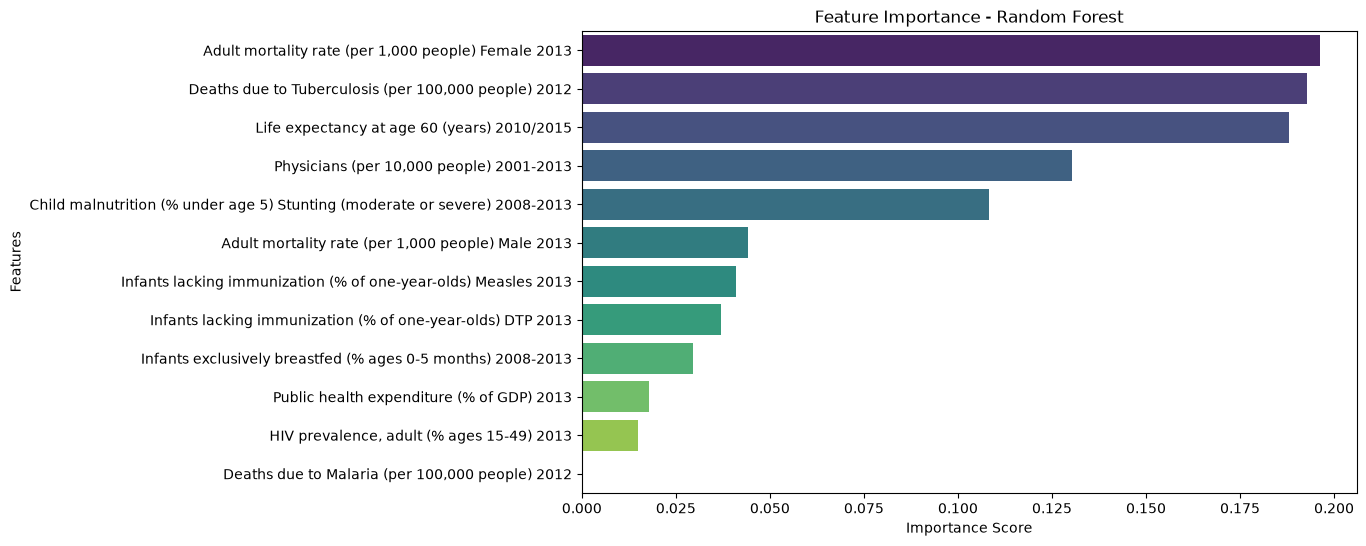

Top 5 Most Important Features:
 Adult mortality rate (per 1,000 people) Female 2013                           0.196248
Deaths due to Tuberculosis (per 100,000 people) 2012                          0.192931
Life expectancy at age 60 (years) 2010/2015                                   0.187998
Physicians (per 10,000 people) 2001-2013                                      0.130421
Child malnutrition (% under age 5) Stunting (moderate or severe) 2008-2013    0.108193
dtype: float64


In [21]:
# Extract and plot feature importances
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances, y=importances.index, palette="viridis")
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

print("Top 5 Most Important Features:\n", importances.head(5))

In [22]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best Hyperparameters:", grid_search.best_params_)
print("Tuned Model Training Accuracy:", grid_search.score(X_train, y_train))
print("Tuned Model Testing Accuracy:", grid_search.score(X_test, y_test))

Best Hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
Tuned Model Training Accuracy: 0.9880952380952381
Tuned Model Testing Accuracy: 0.9761904761904762


In [23]:
import joblib

# Persist the final tuned model
joblib.dump(grid_search.best_estimator_, 'random_forest_health_model.pkl')
print("Model saved successfully as 'random_forest_health_model.pkl'")

Model saved successfully as 'random_forest_health_model.pkl'
